# Tarea 2. Modelación y simulación de procesos estocásticos

**Título de la propuesta:** Estimación del tiempo promedio de resolución de incidencias de soporte TI mediante MCMC

**Institución:** Universidad Juárez del Estado de Durango  
**Programa académico:** Maestría en Estadística Aplicada  
**Asignatura:** Simulación Estocástica  
**Estudiante:** Pedro Said Vara Chacón  
**Docente:** Dr. Gerónimo Quiñonez Barraza

**Fecha de entrega:** Noviembre 15, 2026
**Herramientas utilizadas:** Python, Visual Studio Code, Github.

## 1. Librerías y entorno computacional

Para desarrollar el ejercicio se utilizan las siguientes librerías:

- **NumPy:** generación de números aleatorios y operaciones matemáticas.
- **Pandas:** organización de las estimaciones en tablas.
- **Matplotlib:** elaboración de gráficas.
- **SciPy:** cálculo de una densidad exponencial para comparar con los datos.
- **ArviZ:** cálculo de indicadores para revisar la convergencia de las cadenas.

Se establece la semilla **42** para que los mismos datos y resultados puedan reproducirse al ejecutar nuevamente el notebook. Si ArviZ no está disponible en Colab, primero puede ejecutarse `!pip install arviz` en una celda independiente.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az
from scipy.stats import expon

semilla = 42
rng_datos = np.random.default_rng(semilla)

print('Entorno preparado. Semilla de los datos:', semilla)

Entorno preparado. Semilla de los datos: 42


## 2. Variables de estudio

En el área de tecnologías de la información, los equipos de soporte atienden incidentes como fallas de acceso, errores de configuración o problemas de funcionamiento de aplicaciones. El tiempo necesario para resolverlos puede variar de un caso a otro, por lo que resulta útil estudiar su comportamiento mediante un modelo probabilístico.

La variable de interés es el **tiempo de resolución de una incidencia**, medido en minutos. Es una variable cuantitativa continua cuyo dominio es mayor que cero. Para simplificar el ejercicio, se considera una distribución **exponencial**, que puede representar tiempos positivos con mayor frecuencia de valores pequeños y algunos valores más grandes. Esta es una suposición del modelo, no una propiedad comprobada de todos los servicios de TI.

Como no se cuenta con una base de datos de una mesa de ayuda real, se generarán **40 observaciones simuladas** con un promedio teórico de 25 minutos. Estos datos se emplean únicamente para demostrar el procedimiento y no deben interpretarse como registros reales.

**Objetivo estadístico:** estimar la tasa de resolución $\lambda$ (incidentes por minuto) y, principalmente, el tiempo promedio esperado $\mu=1/\lambda$ (minutos), junto con un intervalo de credibilidad del 95 %.

El siguiente bloque genera los 40 tiempos de ejemplo, presenta las primeras observaciones y calcula su promedio. Se conserva la misma semilla para obtener los mismos valores en cada ejecución.

In [3]:
# Se generan tiempos positivos usando una distribución exponencial.
numero_incidencias = 40
promedio_generador = 25  # Minutos; valor elegido para crear los datos de prueba.
tiempos = rng_datos.exponential(scale=promedio_generador,
                                size=numero_incidencias)

datos = pd.DataFrame({
    'Incidencia': np.arange(1, numero_incidencias + 1),
    'Tiempo_min': np.round(tiempos, 2)
})
print('Primeras 10 observaciones simuladas:')
print(datos.head(10).to_string(index=False))
print(f'\nPromedio observado: {tiempos.mean():.2f} minutos')
print(f'Mínimo: {tiempos.min():.2f}; máximo: {tiempos.max():.2f} minutos')

Primeras 10 observaciones simuladas:
 Incidencia  Tiempo_min
          1       60.11
          2       58.40
          3       59.62
          4        6.99
          5        2.16
          6       36.32
          7       35.25
          8       78.11
          9        1.98
         10       26.16

Promedio observado: 20.96 minutos
Mínimo: 1.76; máximo: 78.11 minutos


## 3. Fundamentos matemáticos y probabilísticos

Una **cadena de Markov** es una sucesión aleatoria en la que la distribución del siguiente estado depende del estado actual. Los métodos Monte Carlo vía cadenas de Markov (MCMC) utilizan esa propiedad para generar valores que, después de un periodo inicial, representan una distribución objetivo.

En este ejercicio se utiliza un enfoque bayesiano. Para cada tiempo observado $t_i$, se propone la distribución exponencial:

$$
f(t_i\mid \lambda)=\lambda e^{-\lambda t_i},\qquad t_i\geq 0,\ \lambda>0.
$$

Aquí, $t_i$ es el tiempo de una incidencia y $\lambda$ es la tasa de resolución. Su media teórica es $\mu=1/\lambda$.

Antes de observar los datos se considera una distribución previa Gamma para $\lambda$, parametrizada por **forma** $a_0=2$ y **tasa** $b_0=40$:

$$
\lambda\sim\operatorname{Gamma}(a_0,b_0),\qquad E(\lambda)=\frac{a_0}{b_0}=0.05.
$$

Esta distribución previa corresponde a una tasa esperada de 0.05 por minuto, equivalente a un tiempo de 20 minutos al tomar su inverso. Es una elección de ejemplo, no conocimiento previo documentado de una empresa. Es importante distinguir que $1/E(\lambda)$ no es lo mismo que $E(1/\lambda)$.

Aplicando la regla de Bayes, la distribución posterior resulta:

$$
\pi(\lambda\mid t_1,\ldots,t_n)
\propto \lambda^{a_0+n-1}
\exp\!\left[-\left(b_0+\sum_{i=1}^{n}t_i\right)\lambda\right].
$$

En este caso corresponde a una Gamma con parámetros $a_0+n$ y $b_0+\sum t_i$. Esta distribución posterior será el objetivo de la simulación.

El **espacio de estados** para la tasa es $(0,\infty)$. Una distribución se considera estacionaria cuando las transiciones de la cadena la conservan. El algoritmo de Metropolis–Hastings está construido para cumplir la condición de equilibrio detallado:

$$
\pi(x)K(x,y)=\pi(y)K(y,x),
$$

donde $K(x,y)$ representa la transición desde un estado $x$ a otro $y$. Se necesita, además, que la cadena pueda recorrer el espacio de interés y no quede atrapada en ciclos fijos. Con estas condiciones y suficientes iteraciones, las muestras permiten aproximar la distribución objetivo.

## 4. Selección del algoritmo MCMC

Se seleccionó **Metropolis–Hastings**, porque puede implementarse con una función relativamente corta y permite trabajar directamente con la distribución posterior. Aunque para este modelo sencillo también sería posible obtener valores Gamma de forma directa, aquí interesa practicar el procedimiento MCMC solicitado.

Como $\lambda$ debe ser positiva, el algoritmo trabaja con $z=\log(\lambda)$; al terminar se recupera $\lambda=e^z$. Se plantea una nueva propuesta mediante:

$$
z^*=z^{(k)}+\varepsilon,\qquad \varepsilon\sim N(0,s^2).
$$

El valor $s$ controla el tamaño de los movimientos. La distribución objetivo para la variable transformada incluye el ajuste por el cambio de variable:

$$
\log \pi_z(z\mid\mathbf{t})= (a_0+n)z-
\left(b_0+\sum_{i=1}^n t_i\right)e^z+C.
$$

Como la propuesta es simétrica en $z$, la probabilidad de aceptación es:

$$
\alpha=\min\left(1,\exp\left[\log\pi_z(z^*)-\log\pi_z(z^{(k)})\right]\right).
$$

En cada iteración se propone un valor; si se acepta, pasa a ser el estado siguiente. Si se rechaza, el estado permanece igual. Se usa el logaritmo de la función objetivo para evitar cálculos innecesarios con números muy pequeños.

## 5. Configuración de la simulación

Se utilizan cuatro cadenas independientes, cada una con **5,000 iteraciones**. Las primeras **1,000 iteraciones** de cada cadena se eliminan como periodo de calentamiento (*burn-in*), de manera que quedan 4,000 valores por cadena y 16,000 en total.

Los valores iniciales de la tasa son 0.01, 0.025, 0.05 y 0.10 incidentes por minuto. Se eligieron diferentes puntos de partida para comprobar si las cadenas terminan explorando una región semejante. La desviación estándar de la propuesta en escala logarítmica es **0.35**, elegida como un valor inicial razonable para este ejemplo.

Estas decisiones no garantizan la convergencia. Por esa razón, más adelante se revisan gráficas e indicadores numéricos para evaluar el comportamiento de las cadenas.

In [4]:
# Parámetros previos y configuración MCMC.
a0 = 2.0
b0 = 40.0  # Tasa de la Gamma; unidades: minutos.
forma_post = a0 + len(tiempos)
tasa_post = b0 + tiempos.sum()

numero_cadenas = 4
iteraciones = 5000
burn_in = 1000
escala_propuesta = 0.35
valores_iniciales = [0.01, 0.025, 0.05, 0.10]

print('Parámetros posteriores:')
print(f'Forma = {forma_post:.0f}; tasa = {tasa_post:.2f}')
print(f'Muestras posteriores previstas = {numero_cadenas * (iteraciones - burn_in)}')

Parámetros posteriores:
Forma = 42; tasa = 878.40
Muestras posteriores previstas = 16000


## 6. Implementación computacional

Primero se define la función que calcula el logaritmo de la distribución objetivo en la escala transformada. Después se programa Metropolis–Hastings. En cada recorrido se almacena la tasa propuesta o retenida y se registra el porcentaje de propuestas aceptadas.

In [5]:
# Logaritmo de la densidad posterior de z = log(lambda).
# La constante de normalización no es necesaria al calcular diferencias.
def log_posterior_z(z):
    return forma_post * z - tasa_post * np.exp(z)


def ejecutar_metropolis(tasa_inicial, n_iter, escala, rng):
    z_actual = np.log(tasa_inicial)
    muestras = np.zeros(n_iter)
    aceptaciones = 0

    for i in range(n_iter):
        # Se propone otro estado cercano en escala logarítmica.
        z_propuesto = rng.normal(loc=z_actual, scale=escala)

        # Diferencia de log-densidades de la propuesta y el estado actual.
        diferencia = log_posterior_z(z_propuesto) - log_posterior_z(z_actual)

        # Se acepta siempre una mejora y a veces una propuesta menos probable.
        if np.log(rng.random()) < min(0.0, diferencia):
            z_actual = z_propuesto
            aceptaciones += 1

        # Se vuelve a la escala original: lambda debe ser positiva.
        muestras[i] = np.exp(z_actual)

    return muestras, aceptaciones / n_iter

Ahora se ejecutan las cuatro cadenas con diferentes valores iniciales. Se utiliza una semilla distinta para cada una, derivada de la semilla principal. Después del calentamiento se transforma cada tasa en tiempo promedio estimado ($\mu=1/\lambda$).

In [6]:
# Ejecutar las cuatro cadenas con semillas reproducibles.
cadenas = []
tasas_aceptacion = []

for i in range(numero_cadenas):
    rng_cadena = np.random.default_rng(semilla + 100 + i)
    cadena, aceptacion = ejecutar_metropolis(
        valores_iniciales[i], iteraciones, escala_propuesta, rng_cadena
    )
    cadenas.append(cadena)
    tasas_aceptacion.append(aceptacion)

cadenas = np.array(cadenas)  # Forma: (cadenas, iteraciones).
cadenas_post = cadenas[:, burn_in:]  # Se elimina el calentamiento.
muestras_mu = 1.0 / cadenas_post  # Tiempo promedio en minutos.

for i, tasa in enumerate(tasas_aceptacion, start=1):
    print(f'Cadena {i}: aceptación = {tasa:.1%}')

print('Forma del arreglo posterior:', muestras_mu.shape)

Cadena 1: aceptación = 47.0%
Cadena 2: aceptación = 47.4%
Cadena 3: aceptación = 45.5%
Cadena 4: aceptación = 47.3%
Forma del arreglo posterior: (4, 4000)


## 7. Diagnóstico de convergencia

Se revisan los siguientes indicadores:

- **R-hat:** compara el comportamiento de las cadenas. Un valor cercano a 1, de preferencia inferior a 1.01, es una señal favorable.
- **ESS:** tamaño efectivo de muestra. Considera que las observaciones de una cadena pueden estar relacionadas entre sí; un valor mayor indica más información útil.
- **MCSE:** error estándar de Monte Carlo. Mide la incertidumbre numérica asociada a estimar la media con una cantidad finita de muestras.

Los tres indicadores se calculan con ArviZ. Posteriormente se revisan las trayectorias de las cadenas y la autocorrelación. Ningún indicador, por sí solo, garantiza convergencia absoluta.

In [7]:
# ArviZ recibe los resultados con dimensiones (cadena, iteración).
# ArviZ cambió algunos argumentos entre versiones; se admiten ambas.
variables_posteriores = {'tiempo_medio': muestras_mu,
                         'tasa_lambda': cadenas_post}
try:
    inferencia = az.from_dict(posterior=variables_posteriores)
    diagnosticos = az.summary(inferencia, var_names=['tiempo_medio'],
                             hdi_prob=0.95, round_to=3)
except TypeError:
    inferencia = az.from_dict({'posterior': variables_posteriores})
    diagnosticos = az.summary(inferencia, var_names=['tiempo_medio'],
                             ci_prob=0.95, round_to=3)
print(diagnosticos[['mean', 'sd', 'ess_bulk', 'ess_tail',
                    'mcse_mean', 'r_hat']].to_string())

rhat = float(diagnosticos.loc['tiempo_medio', 'r_hat'])
ess = float(diagnosticos.loc['tiempo_medio', 'ess_bulk'])
mcse = float(diagnosticos.loc['tiempo_medio', 'mcse_mean'])

                mean     sd  ess_bulk  ess_tail  mcse_mean  r_hat
tiempo_medio  21.399  3.349   3739.45  3733.473      0.055  1.002


**Gráfica de trayectoria.** Se representa el valor del tiempo promedio en cada iteración posterior al calentamiento, para cada una de las cuatro cadenas. El propósito es comprobar que ninguna cadena mantiene una tendencia prolongada o permanece en una zona distinta de las demás.

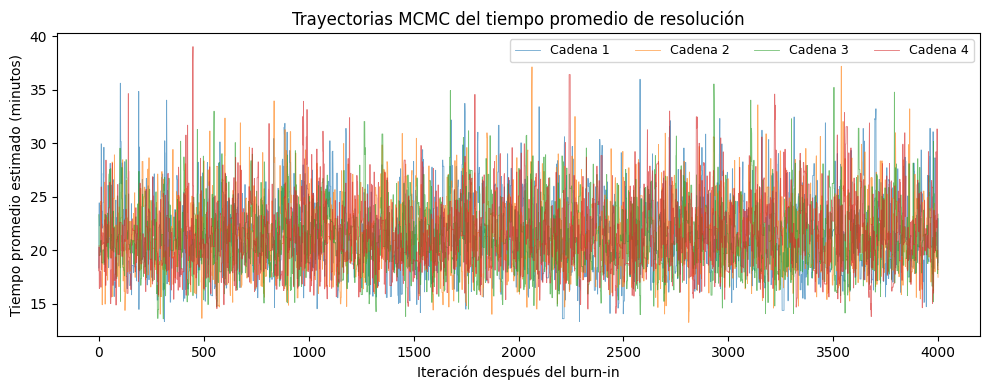

In [8]:
plt.figure(figsize=(10, 4))
for i in range(numero_cadenas):
    plt.plot(muestras_mu[i], linewidth=0.6, alpha=0.65,
             label=f'Cadena {i + 1}')
plt.title('Trayectorias MCMC del tiempo promedio de resolución')
plt.xlabel('Iteración después del burn-in')
plt.ylabel('Tiempo promedio estimado (minutos)')
plt.legend(ncol=4, fontsize=9)
plt.tight_layout()
plt.show()

**Interpretación de la trayectoria.** Las cuatro cadenas fluctúan alrededor de una zona común, sin una tendencia creciente o decreciente persistente. Aunque los valores cambian entre iteraciones, sus trayectorias se superponen. Las medias de las cadenas se ubican entre 21.27 y 21.57 minutos.

**Conclusión de esta gráfica:** La gráfica es compatible con una mezcla razonable de las cadenas después del calentamiento.

**Gráfica de autocorrelación (ACF).** Se calcula la correlación entre valores de una misma cadena separados por diferentes retardos, usando la primera cadena posterior al calentamiento. Se espera que la relación entre iteraciones disminuya a medida que aumenta el retardo.

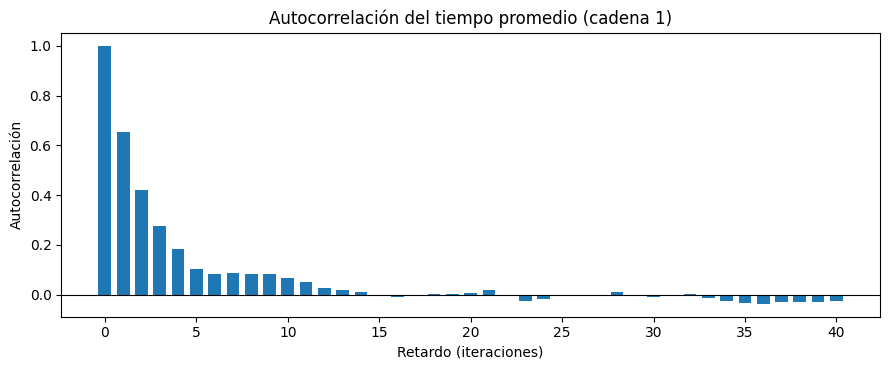

ACF retardo 1: 0.654
ACF retardo 10: 0.068


In [9]:
# Se calcula la ACF en la primera cadena para retardos de 0 a 40.
serie = muestras_mu[0]
retardos = np.arange(41)
autocorrelaciones = [
    1.0 if k == 0 else np.corrcoef(serie[:-k], serie[k:])[0, 1]
    for k in retardos
]

plt.figure(figsize=(9, 3.8))
plt.bar(retardos, autocorrelaciones, width=0.7)
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Autocorrelación del tiempo promedio (cadena 1)')
plt.xlabel('Retardo (iteraciones)')
plt.ylabel('Autocorrelación')
plt.tight_layout()
plt.show()

print(f'ACF retardo 1: {autocorrelaciones[1]:.3f}')
print(f'ACF retardo 10: {autocorrelaciones[10]:.3f}')

**Interpretación de la ACF.** La autocorrelación inicial es positiva (retardo 1 = 0.65), pero disminuye al aumentar el retardo (retardo 10 = 0.07). Esto es esperado porque las muestras MCMC no son independientes una de otra.

**Conclusión de esta gráfica:** La dependencia entre muestras disminuye con la distancia entre iteraciones; por ello conviene utilizar el ESS en lugar de considerar las 16,000 muestras como independientes.

**Evaluación conjunta.** El valor R-hat fue 1.002, el ESS central fue aproximadamente 3739 y el MCSE de la media fue 0.055 minutos. En conjunto, estos resultados apoyan el uso de las muestras para describir la distribución posterior en este ejemplo, sin que ello constituya una garantía absoluta de convergencia.

## 8. Resultados numéricos

Se resumen las 16,000 muestras del tiempo promedio estimado. Se calcularán media, mediana, desviación estándar, varianza y cuantiles del 2.5 %, 25 %, 75 % y 97.5 %. Los cuantiles extremos forman un **intervalo de credibilidad de igual cola del 95 %**.

En la interpretación bayesiana, el intervalo de credibilidad describe los valores plausibles del parámetro bajo los supuestos del modelo y la distribución previa. No representa un intervalo donde deba caer el 95 % de los tiempos individuales.

In [10]:
# Se reúnen las muestras posteriores de las cuatro cadenas.
valores_mu = muestras_mu.ravel()
media_mu = np.mean(valores_mu)
mediana_mu = np.median(valores_mu)
desv_mu = np.std(valores_mu, ddof=1)
var_mu = np.var(valores_mu, ddof=1)
q025, q25, q75, q975 = np.quantile(valores_mu, [0.025, 0.25, 0.75, 0.975])

resultados = pd.DataFrame({
    'Medida': ['Media', 'Mediana', 'Desviación estándar', 'Varianza',
               'Cuantil 2.5 %', 'Cuantil 25 %', 'Cuantil 75 %',
               'Cuantil 97.5 %'],
    'Valor': [media_mu, mediana_mu, desv_mu, var_mu,
              q025, q25, q75, q975],
    'Unidad': ['min', 'min', 'min', 'min²', 'min', 'min', 'min', 'min']
})
resultados['Valor'] = resultados['Valor'].round(2)
print(resultados.to_string(index=False))
print(f'\nIntervalo de credibilidad del 95 %: [{q025:.2f}, {q975:.2f}] min')

             Medida  Valor Unidad
              Media  21.40    min
            Mediana  21.00    min
Desviación estándar   3.35    min
           Varianza  11.22   min²
      Cuantil 2.5 %  15.85    min
       Cuantil 25 %  19.01    min
       Cuantil 75 %  23.45    min
     Cuantil 97.5 %  28.71    min

Intervalo de credibilidad del 95 %: [15.85, 28.71] min


**Interpretación de los resultados.** El tiempo promedio estimado fue 21.40 minutos, con mediana de 21.00 minutos. La desviación estándar posterior fue de 3.35 minutos, lo que describe la incertidumbre sobre el promedio del proceso. El intervalo de credibilidad del 95 % fue de 15.85 a 28.71 minutos. Bajo el modelo y la distribución previa utilizados, este rango contiene los valores más plausibles del tiempo promedio.

## 9. Resultados gráficos

Se incluyen dos gráficas adicionales: primero la distribución de los tiempos simulados y después la distribución posterior del tiempo promedio estimado. La primera ayuda a describir los datos del ejercicio; la segunda representa la incertidumbre sobre el parámetro que se buscó estimar.

**Gráfica de tiempos observados.** Las barras muestran la cantidad de incidencias por intervalo de duración y la curva representa una distribución exponencial usando la tasa promedio estimada con MCMC.

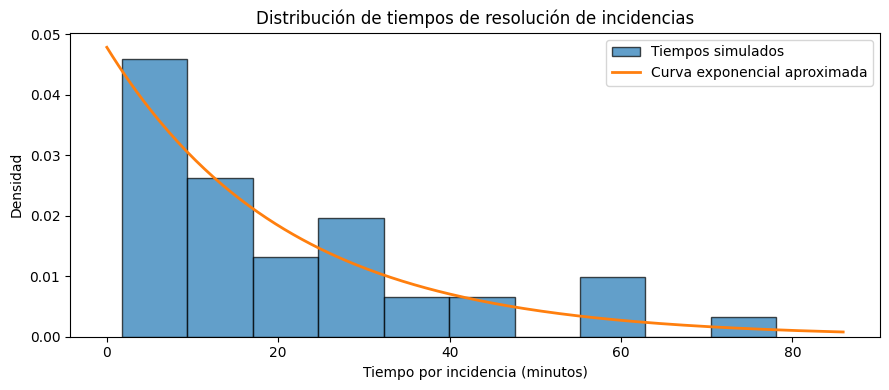

In [10]:
# Gráfica de los datos simulados comparada con una densidad exponencial.
x = np.linspace(0, max(tiempos) * 1.10, 250)
tasa_estimada = np.mean(cadenas_post)

plt.figure(figsize=(9, 4))
plt.hist(tiempos, bins=10, density=True, alpha=0.7,
         edgecolor='black', label='Tiempos simulados')
plt.plot(x, expon.pdf(x, scale=1 / tasa_estimada),
         linewidth=2, label='Curva exponencial aproximada')
plt.title('Distribución de tiempos de resolución de incidencias')
plt.xlabel('Tiempo por incidencia (minutos)')
plt.ylabel('Densidad')
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación del histograma.** La mayor parte de los tiempos simulados se concentra en duraciones relativamente cortas y algunos casos tardan más. El promedio observado en los 40 registros fue de 20.96 minutos. La curva exponencial ofrece una descripción general de esa asimetría, aunque la coincidencia visual no sustituye una prueba formal de ajuste.

**Conclusión de esta gráfica:** La distribución exponencial es una aproximación útil para esta práctica, pero con datos reales sería necesario verificarla.

**Distribución posterior del tiempo promedio.** El histograma presenta los valores de $\mu$ obtenidos con MCMC. La línea central indica la media estimada y las líneas laterales representan los extremos del intervalo de credibilidad del 95 %.

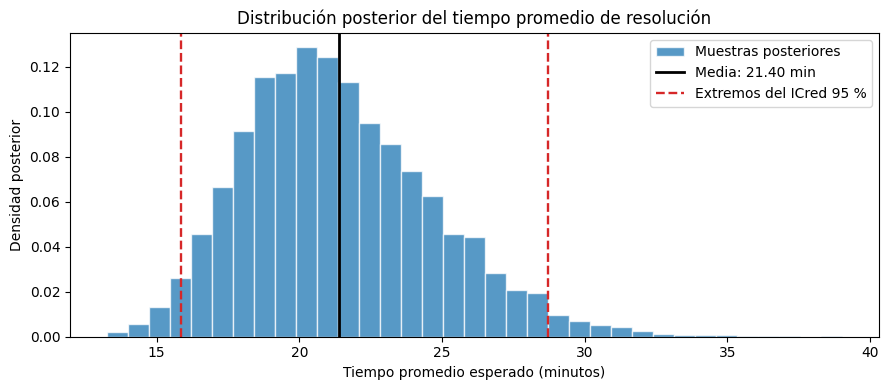

In [11]:
plt.figure(figsize=(9, 4))
plt.hist(valores_mu, bins=35, density=True, alpha=0.75,
         edgecolor='white', label='Muestras posteriores')
plt.axvline(media_mu, color='black', linewidth=2,
            label=f'Media: {media_mu:.2f} min')
plt.axvline(q025, color='tab:red', linestyle='--', linewidth=1.7,
            label='Extremos del ICred 95 %')
plt.axvline(q975, color='tab:red', linestyle='--', linewidth=1.7)
plt.title('Distribución posterior del tiempo promedio de resolución')
plt.xlabel('Tiempo promedio esperado (minutos)')
plt.ylabel('Densidad posterior')
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación de la distribución posterior.** La distribución posterior concentra sus valores alrededor de 21.40 minutos. Las líneas discontinuas señalan un intervalo de credibilidad del 95 % entre 15.85 y 28.71 minutos. La anchura de ese intervalo refleja la incertidumbre que permanece después de considerar 40 observaciones.

**Conclusión de esta gráfica:** MCMC permite estimar el tiempo promedio y expresar su incertidumbre mediante una distribución, no únicamente con un valor puntual.

## 10. Interpretaciones y conclusiones

En esta práctica se implementó el algoritmo Metropolis–Hastings para estudiar el tiempo promedio de resolución de incidencias de soporte TI. A partir de 40 datos simulados, se obtuvo una media posterior de **21.40 minutos** y un intervalo de credibilidad del 95 % de **15.85 a 28.71 minutos**.

Las cuatro cadenas mostraron un comportamiento similar después de eliminar las primeras 1,000 iteraciones. El estadístico R-hat de **1.002**, el ESS central de aproximadamente **3739** y el MCSE de **0.055 minutos** respaldan que la estimación numérica es estable para este ejercicio. La autocorrelación no desaparece inmediatamente, pero disminuye conforme aumenta el retardo.

El ejercicio permitió comprender cómo una cadena de Markov puede utilizarse para aproximar una distribución posterior y calcular medidas de incertidumbre. En una aplicación real, estimar el tiempo promedio de resolución podría servir para establecer objetivos de atención y evaluar cambios en un proceso de soporte, siempre que se usen datos confiables y un modelo adecuado.

**Limitaciones.** Los tiempos fueron generados artificialmente y no describen el desempeño real de una empresa. También se asumió que los 40 tiempos son independientes y siguen una distribución exponencial, lo cual podría no cumplirse en una mesa de ayuda real. La distribución previa fue elegida como ejemplo y no proviene de información histórica. Por otra parte, la convergencia numérica no demuestra que el modelo represente correctamente un proceso real.

**Posibles mejoras.** Como trabajo posterior sería conveniente recopilar tiempos reales, revisar si la distribución exponencial se ajusta a esos registros y comparar con otros modelos, como Gamma o lognormal. También podría estudiarse si el tipo de incidencia o la experiencia del personal influyen en el tiempo de resolución.

## 11. Referencias bibliográficas

ArviZ Development Team. (s. f.). *ArviZ: Exploratory analysis of Bayesian models*. https://python.arviz.org/

Chib, S., & Greenberg, E. (1995). Understanding the Metropolis-Hastings algorithm. *The American Statistician, 49*(4), 327–335. https://doi.org/10.1080/00031305.1995.10476177

Vehtari, A., Gelman, A., Simpson, D., Carpenter, B., & Bürkner, P.-C. (2021). Rank-normalization, folding, and localization: An improved R-hat for assessing convergence of MCMC. *Bayesian Analysis, 16*(2), 667–718. https://doi.org/10.1214/20-BA1221

### Nota sobre la información utilizada

Los datos fueron simulados con Python para fines académicos. No se utilizaron expedientes, registros de clientes ni datos de una organización real.